# 군집화 (RFM · K-Means · DBSCAN)

카페: [군집화(RFM - Kmeans, DBSCAN)](https://cafe.naver.com/f-e/cafes/31780422/articles/626)  
세션 노트: [`session26.md`](../session26.md)

> **쉬운 말**  
> 앞부분은 pandas로 표를 고르는 복습입니다.  
> 이어서 고객마다 **R(최근)·F(횟수)·M(금액)** 을 만든 뒤,  
> **K-Means**와 **DBSCAN**으로 비슷한 고객끼리 묶습니다.  
> 데이터는 `../data/online_retail.csv`로 읽습니다.


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [24]:
df=pd.DataFrame({'이름':['호진','예진','우정'],
                 '색':['red','blue','green'],
                 '순위':[5,3,2]})
df.columns

Index(['이름', '색', '순위'], dtype='str')

In [25]:
df['이름'] #Series

0    호진
1    예진
2    우정
Name: 이름, dtype: str

In [26]:
df[['이름']] #DataFrame

,이름
0,호진
1,예진
2,우정


In [27]:
df[['이름','순위']]

,이름,순위
0,호진,5
1,예진,3
2,우정,2


In [28]:
df['순위']

0    5
1    3
2    2
Name: 순위, dtype: int64

In [29]:
df['순위'] < 3

0    False
1    False
2     True
Name: 순위, dtype: bool

In [30]:
#조건에 맞는 행만 골라냄 -> 불리언 인덱싱
df[df['순위'] < 3]

,이름,색,순위
2,우정,green,2


In [31]:
#색이 red인 데이터만 데이터프레임으로 출력
df[df['색']=='red']

,이름,색,순위
0,호진,red,5


In [32]:
df [(df['순위'] > 2) & (df['순위']) < 5 ]

,이름,색,순위
0,호진,red,5
1,예진,blue,3
2,우정,green,2


In [33]:
df.iloc[0]

이름     호진
색     red
순위      5
Name: 0, dtype: object

In [34]:
df=pd.read_csv("../data/online_retail.csv")
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [35]:
#CustomerID 결측치확인
df['CustomerID'].isna().sum()

np.int64(135080)

In [36]:
#불리언인덱싱 기법(True인 행만 남김) -> null값들은 버림
#값이 있는 행만 df에 재할당
df=df[df['CustomerID'].notnull()]
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [37]:
df['CustomerID'].isna().sum()

np.int64(0)

In [44]:
#(df['Quantity'] > 0 ) & (df['UnitPrice'] > 0) 가 true인 행만 남겨 df에 저장
df=df[(df['Quantity'] > 0 ) & (df['UnitPrice'] > 0)]
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [47]:
print((df['Quantity'] <= 0).sum())
print((df['UnitPrice'] <= 0).sum())

0
0


In [ ]:
#RFM : Recency / Frequency / Monetary

In [75]:
#고객아이디별로 묶어서 해당 고객이 사용한 송장번호의 개수(고유한 개수)뽑으면 고객별 구매한 빈도수 추출할 수 있다.
# reset_index() : 그룹화 결과를 다시 DataFrame으로 변환
frequency_df=df.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
frequency_df.columns=['CustomerID','Frequency']
frequency_df

,CustomerID,Frequency
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
...,...,...
4333,18280.0,1
4334,18281.0,1
4335,18282.0,2
4336,18283.0,16


In [76]:
# data={'가입일' : ['2026-11-04', '2026-11-03']}
# df1=pd.DataFrame(data)

# df1['가입일'] = pd.to_datetime(df1['가입일'])
# df1['가입년도']=df1['가입일'].dt.year
# print(df1['가입년도'])

# df1['가입월']=df1['가입일'].dt.month
# print(df1['가입월'])

# df1['가입일']=df1['가입일'].dt.day
# print(df1['가입일'])

In [77]:
#문자열 -> 날짜형식으로 변환
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])
df['InvoiceDate']

0        2010-12-01 08:26:00
1        2010-12-01 08:26:00
2        2010-12-01 08:26:00
3        2010-12-01 08:26:00
4        2010-12-01 08:26:00
                 ...        
541904   2011-12-09 12:50:00
541905   2011-12-09 12:50:00
541906   2011-12-09 12:50:00
541907   2011-12-09 12:50:00
541908   2011-12-09 12:50:00
Name: InvoiceDate, Length: 397884, dtype: datetime64[us]

In [78]:
#가장 최근에 주문한 날짜
latest=df['InvoiceDate'].max()
latest

Timestamp('2011-12-09 12:50:00')

In [79]:
#고객별로 주문일의 최대값 출력 => 데이터프레임형태
recency_df=df.groupby('CustomerID')['InvoiceDate'].max().reset_index()

#고객별로 며칠전에 구매했는지(가장 최근 주문 날짜 기준으로)
recency_df['Recency']=(latest - recency_df['InvoiceDate']).dt.days
recency_df

,CustomerID,InvoiceDate,Recency
0,12346.0,2011-01-18 10:01:00,325
1,12347.0,2011-12-07 15:52:00,1
2,12348.0,2011-09-25 13:13:00,74
3,12349.0,2011-11-21 09:51:00,18
4,12350.0,2011-02-02 16:01:00,309
...,...,...,...
4333,18280.0,2011-03-07 09:52:00,277
4334,18281.0,2011-06-12 10:53:00,180
4335,18282.0,2011-12-02 11:43:00,7
4336,18283.0,2011-12-06 12:02:00,3


In [80]:
#InvoiceDate 불필요해서 컬럼 제거하기
recency_df.drop('InvoiceDate', axis=1, inplace=True)

C:\Users\hi\AppData\Local\Temp\ipykernel_16740\1168307060.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  recency_df.drop('InvoiceDate', axis=1, inplace=True)


In [81]:
recency_df

,CustomerID,Recency
0,12346.0,325
1,12347.0,1
2,12348.0,74
3,12349.0,18
4,12350.0,309
...,...,...
4333,18280.0,277
4334,18281.0,180
4335,18282.0,7
4336,18283.0,3


In [82]:
recency_df['Recency'].isna().sum()

np.int64(0)

In [83]:
#단가*수량 => TotalPrice컬럼 생성
df['TotalPrice']=df['Quantity']*df['UnitPrice']

#고객별아이디로 그룹화해서 sum()
monetary_df=df.groupby('CustomerID')['TotalPrice'].sum().reset_index()
monetary_df

,CustomerID,TotalPrice
0,12346.0,77183.60
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40
...,...,...
4333,18280.0,180.60
4334,18281.0,80.82
4335,18282.0,178.05
4336,18283.0,2094.88


In [84]:
#R,F,M결합
#R : 며칠전에 구매했냐
#F : 몇번 구매했냐
#M : 얼마나 썼냐

In [85]:
rfm_df=recency_df.merge(frequency_df, on='CustomerID').merge(monetary_df, on='CustomerID')
rfm_df

,CustomerID,Recency,Frequency,TotalPrice
0,12346.0,325,1,77183.60
1,12347.0,1,7,4310.00
2,12348.0,74,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,309,1,334.40
...,...,...,...,...
4333,18280.0,277,1,180.60
4334,18281.0,180,1,80.82
4335,18282.0,7,2,178.05
4336,18283.0,3,16,2094.88


In [86]:
#군집 알고리즘(클러스터링)
from sklearn.cluster import KMeans, DBSCAN
#군집 성능 평가지표
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [87]:
X=rfm_df[['Recency','Frequency','TotalPrice']]
X

,Recency,Frequency,TotalPrice
0,325,1,77183.60
1,1,7,4310.00
2,74,4,1797.24
3,18,1,1757.55
4,309,1,334.40
...,...,...,...
4333,277,1,180.60
4334,180,1,80.82
4335,7,2,178.05
4336,3,16,2094.88


In [88]:
#표준화 
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

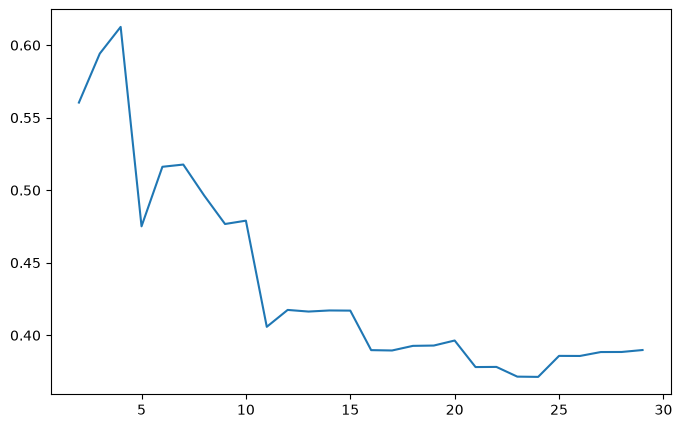

In [91]:
#클러스터링 개수 범위 지정함
#2-29까지 돌려보고 어느 K가 가장 좋은지 확인
k_range=range(2,30)
#각 k값의 점수를 담을 리스트
silhouette_grade=[]

#i개 클러스터로 군집화/ 데이터 학습시키고 각 데이터의 클러스터 라벨 예측
for i in k_range:
    kmeans=KMeans(n_clusters=i, random_state=1)
    #모델학습+클러스터 할당 예측 한번에 수행
    labels=kmeans.fit_predict(X_scaled)
    grade=silhouette_score(X_scaled, labels)
    silhouette_grade.append(grade)

plt.figure(figsize=(8,5))
plt.plot(k_range, silhouette_grade)
plt.show()

In [92]:
silhouette_grade

[0.56042333754011,
 0.5941879366550106,
 0.6126112251227308,
 0.47511778751953077,
 0.516164881940495,
 0.5176982073786867,
 0.49637819657194976,
 0.4767181119068522,
 0.47901484329517086,
 0.40582912943587557,
 0.41747869794796,
 0.4163544730443067,
 0.4171103771042279,
 0.4170010435526701,
 0.38975950281738475,
 0.38951404625779384,
 0.39270156925287014,
 0.3929202033752237,
 0.39639158163617655,
 0.37808618068654337,
 0.3781913952171706,
 0.3714888754956686,
 0.37131372878217483,
 0.3857965736306954,
 0.38573670857924064,
 0.3884415731879478,
 0.3884918776307378,
 0.38983242678873364]

In [93]:
kmeans=KMeans(n_clusters=4, random_state=1)
#4개로 클러스터링 했을때, 각 데이터가 어떤 클러스터에 속하는지 라벨뽑음
rfm_df['ClusterLabel']=kmeans.fit_predict(X_scaled) #[0,1,2,3]
rfm_df

,CustomerID,Recency,Frequency,TotalPrice,ClusterLabel
0,12346.0,325,1,77183.60,2
1,12347.0,1,7,4310.00,0
2,12348.0,74,4,1797.24,0
3,12349.0,18,1,1757.55,0
4,12350.0,309,1,334.40,1
...,...,...,...,...,...
4333,18280.0,277,1,180.60,1
4334,18281.0,180,1,80.82,1
4335,18282.0,7,2,178.05,0
4336,18283.0,3,16,2094.88,0


In [94]:
cluster1=rfm_df.groupby('ClusterLabel').agg({
    'Recency':'mean', #각 클러스터별 Recency평균
    'Frequency':'mean',
    'TotalPrice':'mean',
    'ClusterLabel':'count'
})
cluster1

,Recency,Frequency,TotalPrice,ClusterLabel
ClusterLabel,,,,
0,41.412472,4.136752,1563.782438,3159
1,246.312268,1.552974,556.665949,1076
2,12.406250,34.739583,21702.508229,96
3,5.714286,65.428571,184143.690000,7


In [95]:
pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.7 MB 5.4 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.7 MB 5.3 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 6.7 MB/s eta 0:00:01
   ------------------------ --------------- 6.0/9.7 MB 7.6 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.7 MB 8.3 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 8.3 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [96]:
import plotly.express as pe

In [97]:
fig=pe.scatter_3d(
    rfm_df, x='Recency', y='Frequency', z='TotalPrice', color='ClusterLabel',
    labels={'Recency':'Recency', 'Frequency':'Frequency', 'TotalPrice':'TotalPrice'})

fig.write_html('C:/run/3d.html')

In [98]:
#DBSCAN (밀도기반 클러스터링) : 밀집구역을 클러스터로 찾고 희소 지역은 노이즈로 처리
#eps=0.5, min_samples=5 => 반경0.5안에 이웃점이 5개 이상이면 밀집지역
dbscan=DBSCAN()
#학습시키면서 각 데이터에 클러스터 라벨부여
dbscan_labels=dbscan.fit_predict(X_scaled)
dbscan_labels  #밀집지역 하나로 보면서 덩어리 1개+노이즈 

array([-1,  0,  0, ...,  0,  0,  0], shape=(4338,))

In [100]:
#노이즈 제거 후 유효한 클러스터 개수 확인할거임
drop_noise=dbscan_labels[dbscan_labels!=-1]
unique_label=set(drop_noise)
unique_label #노이즈 뺀 뒤 남은 클러스터 번호 :0 => 클러스터 1개

{np.int64(0)}

In [101]:
#하이퍼 파라미터 튜닝(eps, min_samples)
dbscan=DBSCAN(eps=0.4, min_samples=4)
dbscan_labels=dbscan.fit_predict(X_scaled)
dbscan_labels

array([-1,  0,  0, ...,  0,  0,  0], shape=(4338,))

In [104]:
drop_noise=dbscan_labels[dbscan_labels!=-1]
unique_label=set(drop_noise)

#노이즈 제외된 데이터만 사용 
#클러스터가 2개이상일때만 실루엣 점수 알아냄
if len(unique_label) >=2 :
    dbscan_sil=silhouette_score(X_scaled[dbscan_labels!=-1], drop_noise)
    print(dbscan_sil)

0.7028565405748485


In [105]:
silhouette_score?

Signature:
silhouette_score(
    X,
    labels,
    *,
    metric='euclidean',
    sample_size=None,
    random_state=None,
    **kwds,
)
Docstring:
Compute the mean Silhouette Coefficient of all samples.

The Silhouette Coefficient is calculated using the mean intra-cluster
distance (``a``) and the mean nearest-cluster distance (``b``) for each
sample.  The Silhouette Coefficient for a sample is ``(b - a) / max(a,
b)``.  To clarify, ``b`` is the distance between a sample and the nearest
cluster that the sample is not a part of.
Note that Silhouette Coefficient is only defined if number of labels
is ``2 <= n_labels <= n_samples - 1``.

This function returns the mean Silhouette Coefficient over all samples.
To obtain the values for each sample, use :func:`silhouette_samples`.

The best value is 1 and the worst value is -1. Values near 0 indicate
overlapping clusters. Negative values generally indicate that a sample has
been assigned to the wrong cluster, as a different cluster is more s